In [1]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.db import get_engine

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

In [2]:
engine = get_engine()

df = pd.read_sql(
    "SELECT * FROM dbo.loans_model",
    engine,
    parse_dates=["issue_date", "earliest_cr_line"],
)

df.to_parquet("../data/processed/loans_model.parquet", index=False)

print(df.shape)

(618584, 72)


In [3]:
df.info(memory_usage="deep")

<class 'pandas.DataFrame'>
RangeIndex: 618584 entries, 0 to 618583
Data columns (total 72 columns):
 #   Column                          Non-Null Count   Dtype        
---  ------                          --------------   -----        
 0   id                              618584 non-null  int64        
 1   issue_date                      618584 non-null  datetime64[s]
 2   target                          618584 non-null  int64        
 3   grade                           618584 non-null  str          
 4   sub_grade                       618584 non-null  str          
 5   int_rate                        618584 non-null  float64      
 6   installment                     618584 non-null  float64      
 7   funded_amnt                     618584 non-null  float64      
 8   total_pymnt                     618584 non-null  float64      
 9   loan_amnt                       618584 non-null  float64      
 10  emp_length                      582445 non-null  str          
 11  home_owners

In [4]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
id,618584.0,31553643.653457,54734.0,8561063.25,32038354.5,54177424.75,68616919.0,22989363.98053
issue_date,618584,2014-06-22 17:01:01,2007-06-01 00:00:00,2013-11-01 00:00:00,2014-10-01 00:00:00,2015-07-01 00:00:00,2015-12-01 00:00:00,NaN
target,618584.0,0.138954,0.0,0.0,0.0,0.0,1.0,0.345899
int_rate,618584.0,12.010411,5.32,8.9,11.99,14.35,28.99,3.855785
installment,618584.0,413.964203,14.01,220.61,342.79,544.21,1445.46,259.378226
...,...,...,...,...,...,...,...,...
percent_bc_gt_75,577293.0,48.284764,0.0,16.7,50.0,75.0,100.0,35.653411
tot_hi_cred_lim,566938.0,158594.619854,0.0,42974.0,92992.5,228435.75,9999999.0,172793.430948
total_bal_ex_mort,583463.0,45548.842261,0.0,18727.0,33751.0,56966.5,2921551.0,45324.49482
total_bc_limit,583463.0,20054.982307,0.0,7000.0,13500.0,25900.0,760000.0,20676.559639


In [5]:
counts = df["target"].value_counts()
rates = df["target"].value_counts(normalize=True)

print(pd.DataFrame({"loans": counts, "share": rates.round(4)}))

         loans  share
target               
0       532629  0.861
1        85955  0.139


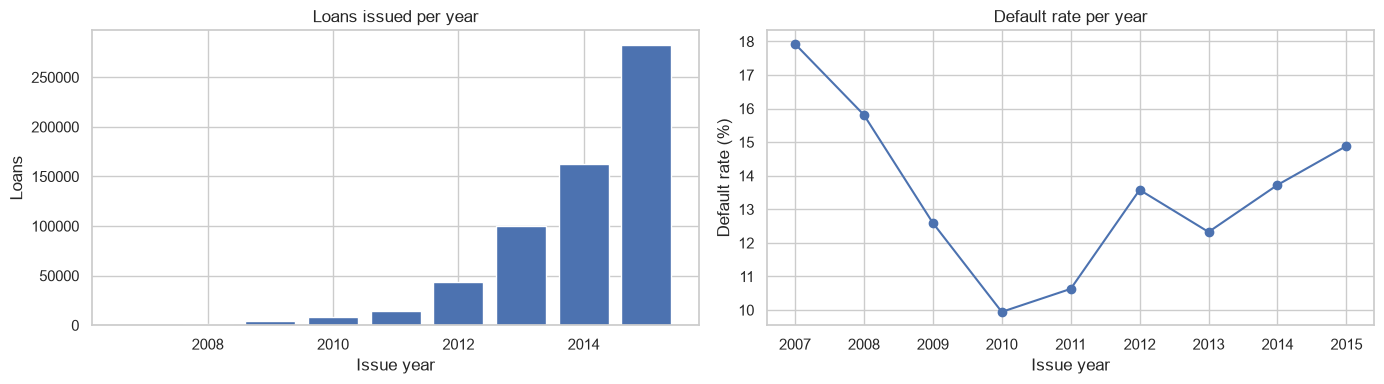

,loans,default_rate
issue_date,,
2007,251,0.179283
2008,1562,0.158131
2009,4716,0.125954
2010,8466,0.099457
2011,14101,0.106305
2012,43470,0.135795
2013,100422,0.123260
2014,162570,0.137264
2015,283026,0.148863


In [6]:
yearly = df.groupby(df["issue_date"].dt.year)["target"].agg(["count", "mean"])
yearly.columns = ["loans", "default_rate"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].bar(yearly.index, yearly["loans"])
axes[0].set_title("Loans issued per year")
axes[0].set_xlabel("Issue year")
axes[0].set_ylabel("Loans")

axes[1].plot(yearly.index, yearly["default_rate"] * 100, marker="o")
axes[1].set_title("Default rate per year")
axes[1].set_xlabel("Issue year")
axes[1].set_ylabel("Default rate (%)")

plt.tight_layout()
plt.savefig("../results/figures/loans_and_default_rate_by_year.png", dpi=120)
plt.show()

yearly

In [7]:
pd.set_option("display.max_rows", 100)

summary = df.describe().T.round(2)
print(summary.to_string())

                                   count                 mean                  min                  25%                  50%                  75%                  max             std
id                              618584.0      31553643.653457              54734.0           8561063.25           32038354.5          54177424.75           68616919.0  22989363.98053
issue_date                        618584  2014-06-22 17:01:01  2007-06-01 00:00:00  2013-11-01 00:00:00  2014-10-01 00:00:00  2015-07-01 00:00:00  2015-12-01 00:00:00             NaN
target                          618584.0             0.138954                  0.0                  0.0                  0.0                  0.0                  1.0        0.345899
int_rate                        618584.0            12.010411                 5.32                  8.9                11.99                14.35                28.99        3.855785
installment                     618584.0           413.964203                14.01   

In [8]:
conditions = {
    "annual_inc == 0": df["annual_inc"] == 0,
    "annual_inc > 1,000,000": df["annual_inc"] > 1_000_000,
    "dti >= 100": df["dti"] >= 100,
    "dti == 999": df["dti"] == 999,
    "dti is null": df["dti"].isna(),
    "revol_util > 100": df["revol_util"] > 100,
    "bc_util > 100": df["bc_util"] > 100,
    "total_rev_hi_lim == 9,999,999": df["total_rev_hi_lim"] == 9_999_999,
    "tot_hi_cred_lim == 9,999,999": df["tot_hi_cred_lim"] == 9_999_999,
    "funded_amnt < loan_amnt": df["funded_amnt"] < df["loan_amnt"],
    "total_pymnt == 0": df["total_pymnt"] == 0,
}

rows = []
for name, mask in conditions.items():
    rows.append({
        "check": name,
        "rows": mask.sum(),
        "default_rate": df.loc[mask, "target"].mean(),
    })

checks = pd.DataFrame(rows).set_index("check")
checks["default_rate"] = (checks["default_rate"] * 100).round(1)
checks

,rows,default_rate
check,,
annual_inc == 0,2,50.0
"annual_inc > 1,000,000",112,8.0
dti >= 100,5,0.0
dti == 999,1,0.0
dti is null,2,50.0
revol_util > 100,2203,19.5
bc_util > 100,10633,20.8
"total_rev_hi_lim == 9,999,999",3,0.0
"tot_hi_cred_lim == 9,999,999",6,16.7


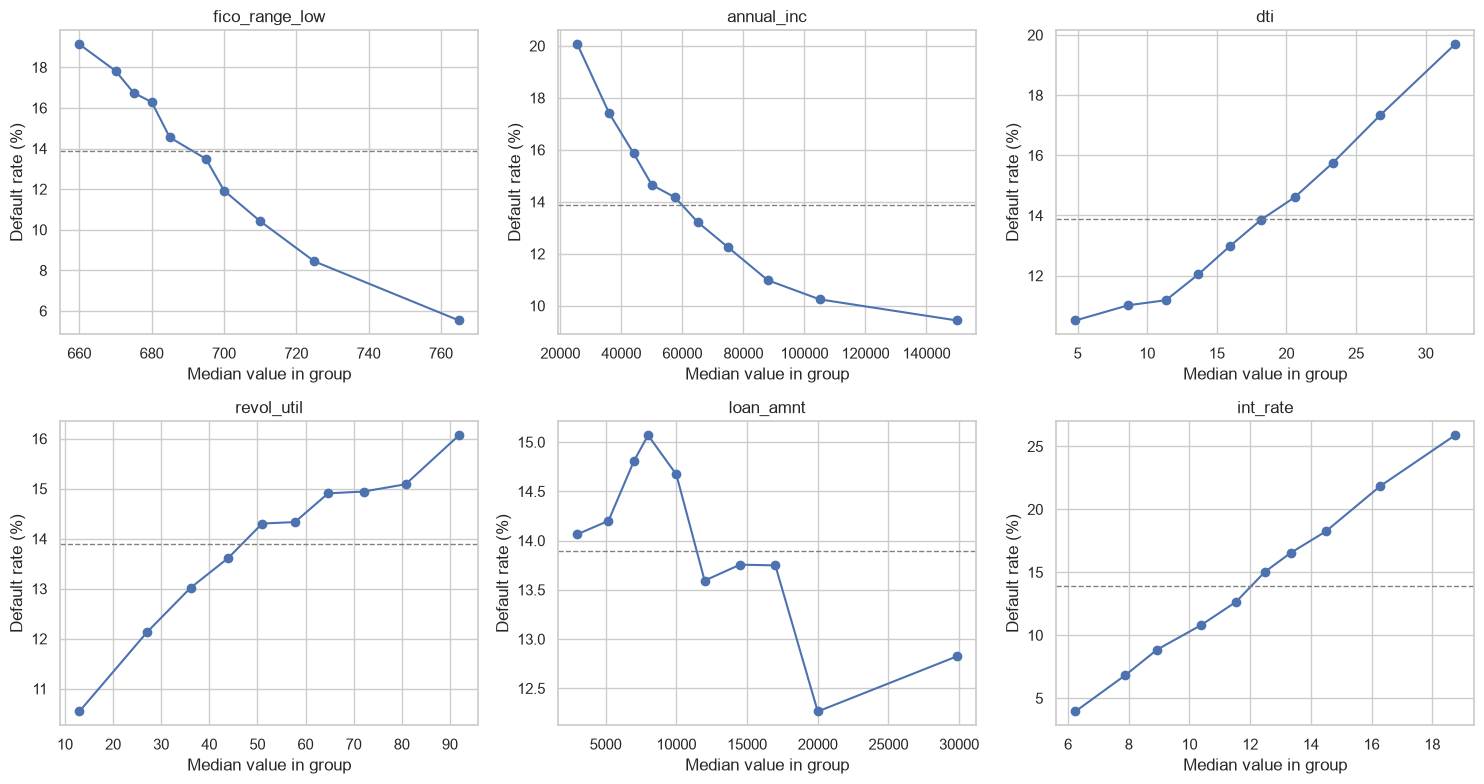

In [9]:
features_to_plot = [
    "fico_range_low", "annual_inc", "dti",
    "revol_util", "loan_amnt", "int_rate",
]

overall_rate = df["target"].mean() * 100

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, col in zip(axes.flat, features_to_plot):
    bins = pd.qcut(df[col], q=10, duplicates="drop")
    grouped = df.groupby(bins, observed=True).agg(
        median_value=(col, "median"),
        default_rate=("target", "mean"),
    )

    ax.plot(grouped["median_value"], grouped["default_rate"] * 100, marker="o")
    ax.axhline(overall_rate, color="gray", linestyle="--", linewidth=1)
    ax.set_title(col)
    ax.set_xlabel("Median value in group")
    ax.set_ylabel("Default rate (%)")

plt.tight_layout()
plt.savefig("../results/figures/default_rate_by_numeric_feature.png", dpi=120)
plt.show()

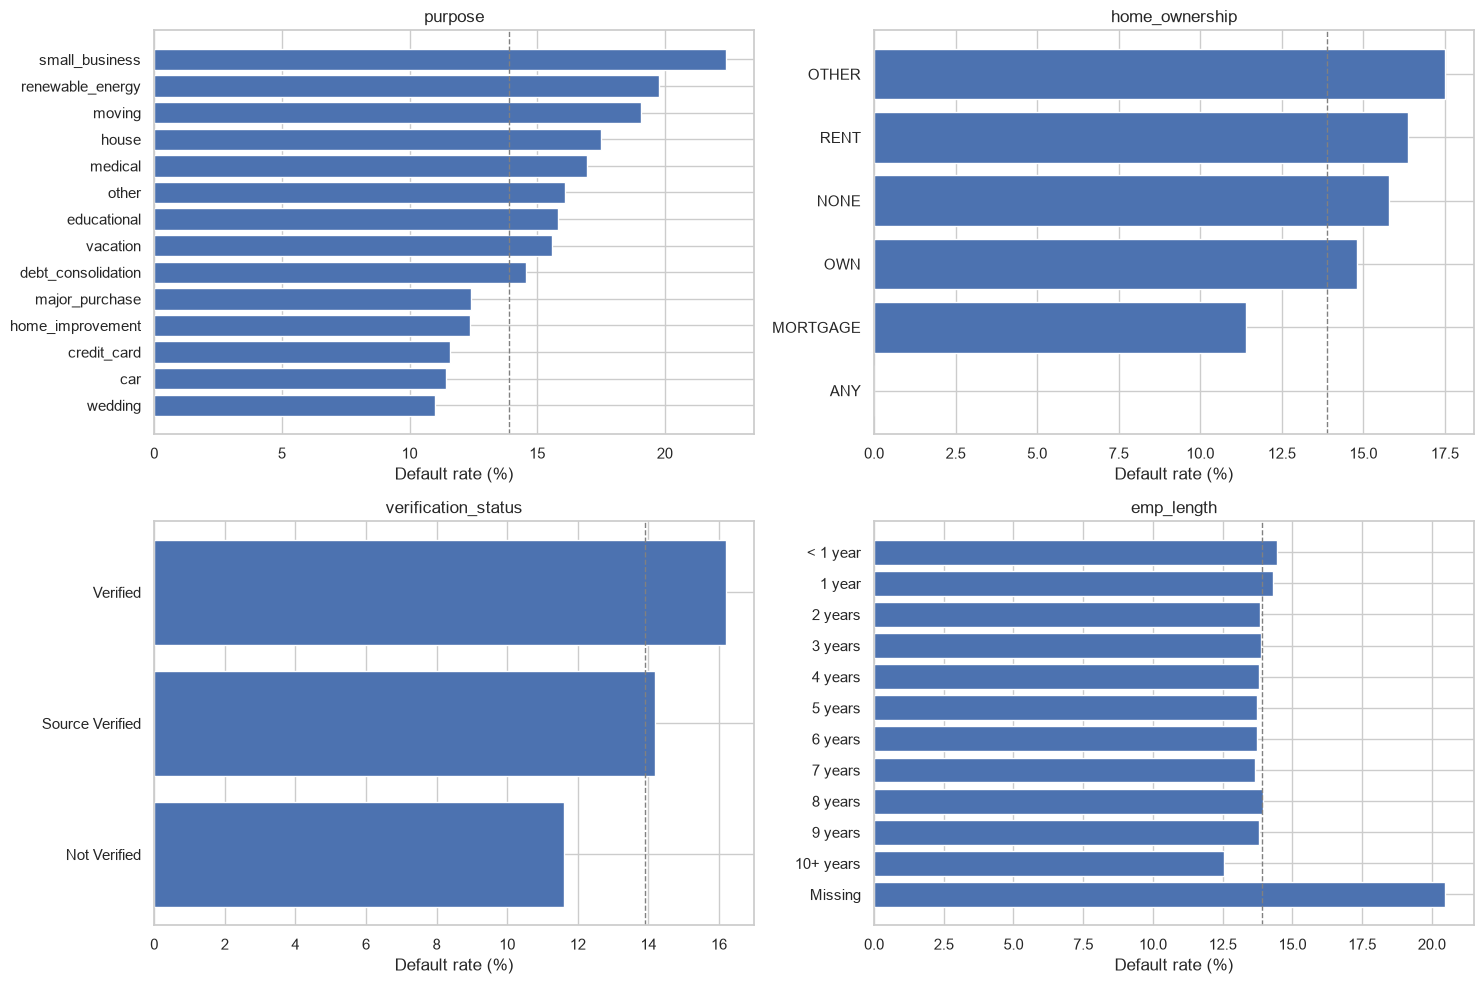


purpose


,loans,default_rate
purpose,,
debt_consolidation,350811,0.145725
credit_card,150085,0.116054
home_improvement,35647,0.123741
other,33708,0.161060
major_purchase,12924,0.124033
small_business,7404,0.223798
medical,6910,0.169609
car,6902,0.114170
moving,4622,0.190610



home_ownership


,loans,default_rate
home_ownership,,
MORTGAGE,287274,0.113905
RENT,268253,0.163588
OWN,62880,0.148219
OTHER,137,0.175182
NONE,38,0.157895
ANY,2,0.000000



verification_status


,loans,default_rate
verification_status,,
Source Verified,217766,0.141987
Not Verified,215601,0.116210
Verified,185217,0.161864



emp_length


,loans,default_rate
emp_length,,
10+ years,190343,0.125484
2 years,56859,0.138219
< 1 year,51474,0.144481
3 years,50440,0.138640
1 year,41678,0.143193
5 years,39482,0.137252
4 years,37590,0.138175
Missing,36139,0.204876
7 years,30804,0.136703


In [10]:
def default_rate_by_category(column):
    return (
        df[column]
        .fillna("Missing")
        .to_frame()
        .assign(target=df["target"])
        .groupby(column)["target"]
        .agg(loans="count", default_rate="mean")
    )


emp_length_order = [
    "< 1 year", "1 year", "2 years", "3 years", "4 years", "5 years",
    "6 years", "7 years", "8 years", "9 years", "10+ years", "Missing",
]

cat_features = ["purpose", "home_ownership", "verification_status", "emp_length"]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for ax, col in zip(axes.flat, cat_features):
    table = default_rate_by_category(col)

    if col == "emp_length":
        table = table.reindex(emp_length_order)
    else:
        table = table.sort_values("default_rate", ascending=False)

    ax.barh(table.index, table["default_rate"] * 100)
    ax.axvline(overall_rate, color="gray", linestyle="--", linewidth=1)
    ax.invert_yaxis()
    ax.set_title(col)
    ax.set_xlabel("Default rate (%)")

plt.tight_layout()
plt.savefig("../results/figures/default_rate_by_category.png", dpi=120)
plt.show()

for col in cat_features:
    print(f"\n{col}")
    display(default_rate_by_category(col).sort_values("loans", ascending=False))

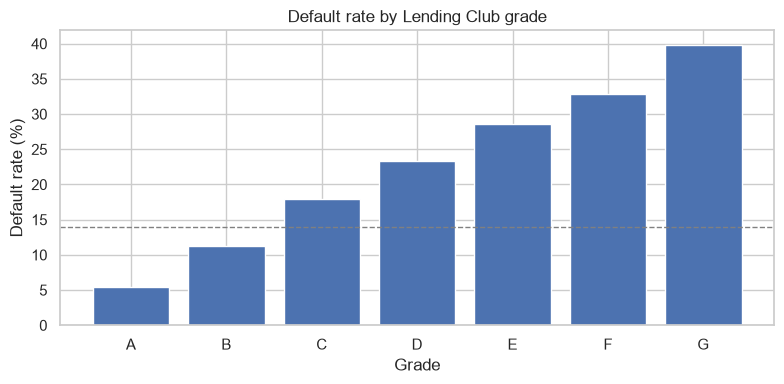

,loans,default_rate
grade,,
A,142911,0.054754
B,211634,0.111920
C,161809,0.179131
D,76045,0.233270
E,21403,0.285661
F,4263,0.328173
G,519,0.398844


In [11]:
grade_table = default_rate_by_category("grade").sort_index()

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(grade_table.index, grade_table["default_rate"] * 100)
ax.axhline(overall_rate, color="gray", linestyle="--", linewidth=1)
ax.set_title("Default rate by Lending Club grade")
ax.set_xlabel("Grade")
ax.set_ylabel("Default rate (%)")

plt.tight_layout()
plt.savefig("../results/figures/default_rate_by_grade.png", dpi=120)
plt.show()

grade_table

In [12]:
state_table = default_rate_by_category("addr_state").sort_values("default_rate")

print("Number of states:", len(state_table))
print("\nSafest 8 states:")
display(state_table.head(8))
print("\nRiskiest 8 states:")
display(state_table.tail(8))
print("\nSmallest 8 states by loan count:")
display(state_table.sort_values("loans").head(8))

Number of states: 51

Safest 8 states:


,loans,default_rate
addr_state,,
NH,2952,0.092141
DC,1822,0.094951
VT,1237,0.100243
ME,338,0.103550
WV,2746,0.103787
KS,5351,0.109325
WY,1371,0.110139
ID,9,0.111111



Riskiest 8 states:


,loans,default_rate
addr_state,,
ND,311,0.157556
TN,8458,0.160440
AL,7296,0.162555
OK,5474,0.167519
AR,4552,0.170035
NV,9169,0.173847
MS,2493,0.186522
NE,761,0.195795



Smallest 8 states by loan count:


,loans,default_rate
addr_state,,
IA,7,0.142857
ID,9,0.111111
ND,311,0.157556
ME,338,0.103550
NE,761,0.195795
VT,1237,0.100243
SD,1279,0.154808
WY,1371,0.110139


In [13]:
import numpy as np

non_feature_columns = [
    "id", "issue_date", "target", "grade", "sub_grade",
    "int_rate", "installment", "funded_amnt", "total_pymnt",
]
feature_columns = [c for c in df.columns if c not in non_feature_columns]

numeric_features = df[feature_columns].select_dtypes("number").columns
corr = df[numeric_features].corr()

upper_triangle = np.triu(np.ones(corr.shape, dtype=bool), k=1)

pairs = (
    corr.where(upper_triangle)
    .stack()
    .rename("correlation")
    .reset_index()
)
pairs.columns = ["feature_1", "feature_2", "correlation"]

high_pairs = (
    pairs[pairs["correlation"].abs() > 0.9]
    .sort_values("correlation", key=abs, ascending=False)
)

print("Numeric features checked:", len(numeric_features))
high_pairs

Numeric features checked: 57


,feature_1,feature_2,correlation
233,fico_range_low,fico_range_high,1.000000
616,open_acc,num_sats,0.998605
2268,num_actv_rev_tl,num_rev_tl_bal_gt_0,0.984975
1307,tot_cur_bal,tot_hi_cred_lim,0.972585


## EDA summary

**Dataset:** 618,584 36-month Lending Club loans issued 2007–2015, 72 columns, 13.9% default rate.

**Time effects**
- Loan volume grows sharply over time; half of all loans were issued after October 2014.
- Default rate falls from ~18% (2007) to ~10% (2010), then rises to ~15% (2015). The test period will be riskier than training (drift).

**Strongest numeric signals**
- FICO: default falls from ~19% (lowest decile) to ~5.5% (highest).
- Annual income: ~20% to ~9.5%, with a diminishing effect at high incomes (use log for logistic regression).
- DTI: ~10.5% to ~19.7%. Revolving utilization: ~10.5% to ~16%.
- Loan amount alone is weak and non-monotonic (confounded by income), so create loan-to-income.

**Categorical signals**
- Purpose: small_business riskiest (22.4%); credit_card, car, wedding safest (~11%).
- Home ownership: MORTGAGE safest (11.4%), RENT riskiest (16.4%).
- Verification: Verified loans default more (16.2%) than Not Verified (11.6%), likely because Lending Club verified riskier applicants.
- Employment length: nearly flat across 1–9 years; missing values default far more (20.5%), so keep a missing flag.
- State: ~9% to ~20%; states with very few loans are unreliable.

**Benchmark:** Lending Club grade separates risk strongly (A 5.5% → G 39.9%).

**Data quality**
- Placeholders to set as missing: annual_inc = 0, dti = 999, credit limits = 9,999,999.
- Real extreme values (high incomes, utilization > 100%) are kept; utilization > 100% is a strong risk signal.
- Nulls in `mths_since_*` mean "never happened", not unknown.

**Redundant features:** fico low/high → fico_avg; drop num_sats, num_rev_tl_bal_gt_0, tot_hi_cred_lim (add total_bal_to_limit).